In [16]:
import tictactoe
import pandas as pd
import matplotlib.pyplot as plt
RUNS = 1000

In [17]:
def play_match(x_name, o_name, x, o):
    """Play RUNS games. Returns per-move search stats and one result row per game."""
    steps = []
    games = []
    match = f"{x_name} vs {o_name}"
    for _ in range(RUNS):
        start = {
            seat: len(player.nodesExplored())
            for seat, player in (("X", x), ("O", o))
            if isinstance(player, tictactoe.MinimaxPlayer)
        }
        result = tictactoe.Game(x, o).run()
        games.append({"match": match, "result": result.name})
        for seat, player, first in (("X", x, 1), ("O", o, 2)):
            if seat not in start:
                continue
            nodes = player.nodesExplored()[start[seat]:]
            times = player.decisionTime()[start[seat]:]
            for i, (n, ns) in enumerate(zip(nodes, times)):
                steps.append({
                    "match": match,
                    "step": first + 2 * i,
                    "nodes": n,
                    "ms": ns / 1e6,
                })
    return steps, games

matches = [
    ("random", "random", tictactoe.RandomPlayer(seed=1), tictactoe.RandomPlayer(seed=2)),
    ("random", "minmax_prune_depth", tictactoe.RandomPlayer(seed=1), tictactoe.MinimaxPlayer(prune=True, useDepth=True)),
    ("minmax_prune_depth", "random", tictactoe.MinimaxPlayer(prune=True, useDepth=True), tictactoe.RandomPlayer(seed=1)),
    ("minmax_prune_depth", "minmax_prune_depth", tictactoe.MinimaxPlayer(prune=True, useDepth=True), tictactoe.MinimaxPlayer(prune=True, useDepth=True)),
]

step_records = []
game_rows = []
for x_name, o_name, x, o in matches:
    steps_part, games_part = play_match(x_name, o_name, x, o)
    step_records += steps_part
    game_rows += games_part

steps = pd.DataFrame(step_records)
avg = (
    steps.groupby(["match", "step"], as_index=False)[["nodes", "ms"]]
    .mean()
    .sort_values("step")
)
df = pd.DataFrame(game_rows)
outcomes = (
    pd.crosstab(df["match"], df["result"], normalize="index")
    .reindex(columns=["Xwin", "Owin", "Tie"])
    .reindex([f"{x_name} vs {o_name}" for x_name, o_name, *_rest in matches])
)
outcomes

result,Xwin,Owin,Tie
match,,,
random vs random,0.581,0.291,0.128
random vs minmax_prune_depth,0.000,0.787,0.213
minmax_prune_depth vs random,0.997,0.000,0.003
minmax_prune_depth vs minmax_prune_depth,0.000,0.000,1.000


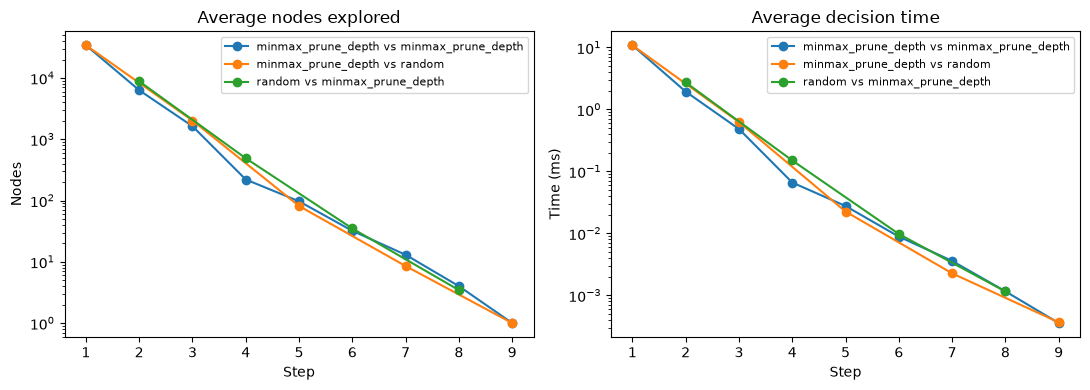

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for match, group in avg.groupby("match", sort=False):
    axes[0].plot(group["step"], group["nodes"], marker="o", label=match)
    axes[1].plot(group["step"], group["ms"], marker="o", label=match)

axes[0].set_title("Average nodes explored")
axes[0].set_ylabel("Nodes")
axes[1].set_title("Average decision time")
axes[1].set_ylabel("Time (ms)")

for ax in axes:
    ax.set_xlabel("Step")
    ax.set_xticks(range(1, 10))
    ax.set_yscale("log")
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

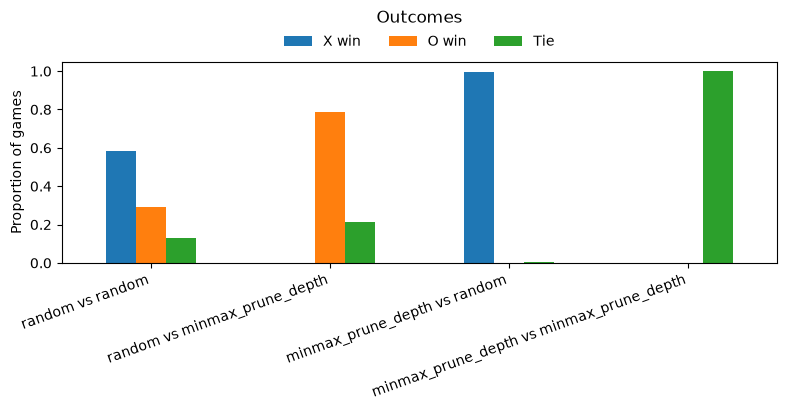

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.2))
outcomes.rename(columns={"Xwin": "X win", "Owin": "O win", "Tie": "Tie"}).plot.bar(ax=ax)
ax.set_ylabel("Proportion of games")
ax.set_xlabel("")
ax.set_title("Outcomes", pad=28)
ax.set_xticklabels(outcomes.index, rotation=20, ha="right")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

In [ ]:
prune_records = []
for label, prune in (("prune", True), ("no prune", False)):
    steps_part, _games = play_match(
        label,
        label,
        tictactoe.MinimaxPlayer(prune=prune, useDepth=True),
        tictactoe.MinimaxPlayer(prune=prune, useDepth=True),
    )
    for row in steps_part:
        row["search"] = label
    prune_records += steps_part

prune_avg = (
    pd.DataFrame(prune_records)
    .groupby(["search", "step"], as_index=False)[["nodes", "ms"]]
    .mean()
    .sort_values("step")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for search, group in prune_avg.groupby("search", sort=False):
    axes[0].plot(group["step"], group["nodes"], marker="o", label=search)
    axes[1].plot(group["step"], group["ms"], marker="o", label=search)

axes[0].set_title("Average nodes explored")
axes[0].set_ylabel("Nodes")
axes[1].set_title("Average decision time")
axes[1].set_ylabel("Time (ms)")
for ax in axes:
    ax.set_xlabel("Step")
    ax.set_xticks(range(1, 10))
    ax.set_yscale("log")
    ax.legend()
fig.tight_layout()
plt.show()